In [1]:
from pathlib import Path
import shutil
import os
import sys

INPUT = Path("/kaggle/input")

# 1. Автоматически находим корень проекта по pyproject.toml + src/
CODE_ROOT = next(
    p.parent
    for p in INPUT.rglob("pyproject.toml")
    if (p.parent / "src").is_dir()
)

# 2. Автоматически находим dataset с данными
DATA_ROOT = next(
    p
    for p in INPUT.rglob("data")
    if p.is_dir() and CODE_ROOT not in p.parents and p != CODE_ROOT / "data"
)

print("CODE_ROOT =", CODE_ROOT)
print("DATA_ROOT =", DATA_ROOT)

# 3. Копируем код в writable-папку
PROJECT_ROOT = Path("/kaggle/working/project")

if PROJECT_ROOT.exists():
    shutil.rmtree(PROJECT_ROOT)

shutil.copytree(CODE_ROOT, PROJECT_ROOT)

# 4. Подставляем Kaggle-данные вместо project/data
project_data = PROJECT_ROOT / "data"

if project_data.exists():
    if project_data.is_dir():
        shutil.rmtree(project_data)
    else:
        project_data.unlink()

project_data.symlink_to(DATA_ROOT, target_is_directory=True)

# 5. Переходим в проект
os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print()
print("READY")
print("cwd:", Path.cwd())
print("src:", (PROJECT_ROOT / "src").exists())
print("configs:", (PROJECT_ROOT / "configs").exists())
print("data ->", (PROJECT_ROOT / "data").resolve())

CODE_ROOT = /kaggle/input/datasets/sevaperetiatko/myfiles
DATA_ROOT = /kaggle/input/datasets/sevaperetiatko/mydata/data

READY
cwd: /kaggle/working/project
src: True
configs: True
data -> /kaggle/input/datasets/sevaperetiatko/mydata/data


# ResNet50 + AGMFA — один эксперимент

[AGMFA paper](https://www.mdpi.com/2072-4292/13/16/3113), разделы 3.1–3.3.
Изменённый layer4 сохраняет 16×16. Три независимые channel-spatial attention masks
из выходов его bottleneck-блоков перемножаются и направляют fusion Res2/Res3/Res4.
Это не CBAM только поверх последнего слоя.

Наши адаптации: полный кадр 256×256; pretrained IMAGENET1K_V2; partial layer3/layer4;
замороженный backbone BatchNorm; новая fusion-нормализация GroupNorm(32,512).
В статье тип нормализации/ширина fusion явно не определены; здесь это фиксированные
настройки. Res4_1/2/3 — полные 2048-канальные bottleneck outputs, не внутренние
512-канальные conv2 tensors. Concat не требует одинакового количества каналов:
512+1024+2048 → 1×1 conv → 512 → ReLU → GroupNorm → GAP → dropout0.3 → FC20.

Robust AugMix+D4 сохранён без изменений, MixStyle выключен. CE, AdamW,
backbone LR5e-5/head LR5e-4, WD0.001, cosine25/eta_min1e-6, seed42.
25 эпох: первые 3 — warmup новых attention/fusion/head; далее также layer3/layer4.
Val только для оценки и выбора best checkpoint, без augmentation/TTA. **Test не читается.**
Обучение по умолчанию выключено; старые эксперименты и checkpoint не меняются.


In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import torch
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Укажите ROOT: корень проекта с src и configs')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.experiment import load_config, run_experiment
from src.models.agmfa_checks import check_agmfa
from src.utils import get_device, plot_history


In [2]:
CONFIG = ROOT / 'configs/resnet50_agmfa_robust_augmix.json'
EXP_ID = 'resnet50_agmfa_robust_augmix_001'
RAW_DIR = ROOT / 'data/raw'  # На Kaggle укажите каталог с train/, val/, classes.csv
DEVICE = 'auto'
BATCH_SIZE = 32  # Если не хватает GPU памяти, поставьте 16 перед запуском
NUM_WORKERS = 2
CPU_THREADS = 4
RUN_PREFLIGHT = True  # True: две synthetic проверки настоящего ResNet50, без данных
RUN_TRAINING = False   # True: один запуск обучения; preflight выполнится первым

device = get_device(DEVICE)
if device.type == 'cpu':
    torch.set_num_threads(CPU_THREADS)
cfg = load_config(CONFIG)
cfg['data'].update(raw_dir=str(RAW_DIR), batch_size=BATCH_SIZE,
                   num_workers=NUM_WORKERS if device.type == 'cuda' else 0)
cfg['training']['device'] = str(device)
print('Device:', device, '| experiment:', EXP_ID)
print('Artifacts:', ROOT / 'artifacts', '| train only, no test/TTA')


Device: cpu | experiment: resnet50_agmfa_robust_augmix_001
Artifacts: C:\Users\peret\Desktop\Third year\ML\comp\comp 2\artifacts | train only, no test/TTA


## Проверка до обучения
Проверка использует настоящую torchvision ResNet50 со случайными backbone весами:
скачивание ImageNet weights и чтение датасета не нужны. Два synthetic optimizer steps
проверяют размеры, product masks, градиенты всех attention, warmup, partial,
неизменность ранних весов и BN buffers, LR groups и deterministic validation.
При самом обучении загружаются pretrained IMAGENET1K_V2.


In [5]:
if RUN_PREFLIGHT or RUN_TRAINING:
    preflight = check_agmfa(cfg, device=str(device), batch_size=2)
    print(json.dumps(preflight, indent=2))
else:
    print('Preflight выключен: RUN_PREFLIGHT = True для проверки.')


{
  "device": "cuda",
  "shapes": {
    "res2": [
      2,
      512,
      32,
      32
    ],
    "res3": [
      2,
      1024,
      16,
      16
    ],
    "semantic_mask": [
      2,
      1,
      16,
      16
    ],
    "concatenated": [
      2,
      3584,
      16,
      16
    ],
    "fused_map": [
      2,
      512,
      16,
      16
    ],
    "fused_features": [
      2,
      512
    ],
    "logits": [
      2,
      20
    ],
    "res4_1": [
      2,
      2048,
      16,
      16
    ],
    "channel_mask_1": [
      2,
      2048,
      1,
      1
    ],
    "spatial_mask_1": [
      2,
      1,
      16,
      16
    ],
    "res4_2": [
      2,
      2048,
      16,
      16
    ],
    "channel_mask_2": [
      2,
      2048,
      1,
      1
    ],
    "spatial_mask_2": [
      2,
      1,
      16,
      16
    ],
    "res4_3": [
      2,
      2048,
      16,
      16
    ],
    "channel_mask_3": [
      2,
      2048,
      1,
      1
    ],
    "spatial_mask_3

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 198MB/s]


resnet50_agmfa_robust_augmix_001 | resnet50_agmfa | device=cuda | seed=42
Epoch 1/25 | train loss=1.5250 acc=0.5663 | val loss=0.7884 acc=0.7868 | lr={'backbone': 5e-05, 'head': 0.0005} | mode=head_only | 107.5s
Epoch 2/25 | train loss=0.6834 acc=0.8108 | val loss=0.5596 acc=0.8455 | lr={'backbone': 4.9806810182204715e-05, 'head': 0.0004980326179779622} | mode=head_only | 87.7s
Epoch 4/25 | train loss=0.3770 acc=0.8844 | val loss=0.2866 acc=0.9113 | lr={'backbone': 4.827952390426216e-05, 'head': 0.0004824792332291187} | mode=partial | 94.6s
Epoch 6/25 | train loss=0.1775 acc=0.9448 | val loss=0.2354 acc=0.9213 | lr={'backbone': 4.532091636218621e-05, 'head': 0.0004523497400965494} | mode=partial | 94.3s
Epoch 8/25 | train loss=0.1168 acc=0.9618 | val loss=0.1912 acc=0.9328 | lr={'backbone': 4.111688774884289e-05, 'head': 0.00040953728544229807} | mode=partial | 94.1s
Epoch 10/25 | train loss=0.0777 acc=0.9786 | val loss=0.1656 acc=0.9471 | lr={'backbone': 3.5931592643344276e-05, 'head'

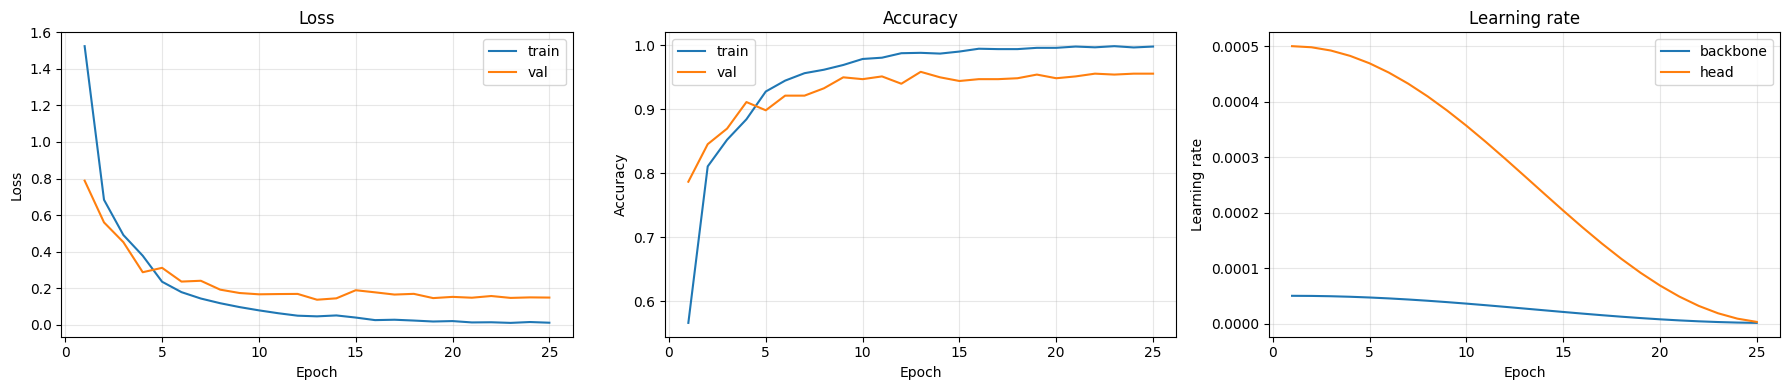

Best epoch: 13; val Accuracy: 95.8512%
{'models': '/kaggle/working/project/artifacts/models/resnet50_agmfa_robust_augmix_001', 'predictions': '/kaggle/working/project/artifacts/predictions/resnet50_agmfa_robust_augmix_001', 'logs': '/kaggle/working/project/artifacts/logs/resnet50_agmfa_robust_augmix_001'}


In [6]:
if RUN_TRAINING:
    result = run_experiment(cfg, EXP_ID, project_root=ROOT,
                            show_plots=True, predict_test=False)
    print(f'Best epoch: {result.best_epoch}; val Accuracy: {result.val_accuracy:.4%}')
    print({name: str(path) for name, path in result.paths.items()})
else:
    print('Обучение выключено. Для одного запуска: RUN_TRAINING = True.')


## Сохранённый результат
Best/last checkpoint: `artifacts/models/<EXP_ID>/`.
History, summary, training.log и графики: `artifacts/logs/<EXP_ID>/`.
Val answers и `val_probabilities.npz`: `artifacts/predictions/<EXP_ID>/`.
После успешного запуска общий pipeline добавит запись в `experiments.csv`.
Следующая ячейка читает готовый результат, повторно ничего не обучает.
Сравнение с другими моделями выполняйте на той же обычной val, без TTA.


In [7]:
logs = ROOT / 'artifacts/logs' / EXP_ID
if (logs / 'summary.json').is_file():
    summary = json.loads((logs / 'summary.json').read_text(encoding='utf-8'))
    display(pd.DataFrame([{'exp_id': EXP_ID, **summary}]))
    history = pd.read_csv(logs / 'history.csv')
    display(history.tail(3))
    if not RUN_TRAINING:
        plot_history(history, show=True)
else:
    print('Результат пока отсутствует. Выполните один запуск на Kaggle.')


,exp_id,best_epoch,val_accuracy,train_time_min
0,resnet50_agmfa_robust_augmix_001,13,0.958512,39.106659


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,next_learning_rate,learning_rates,next_learning_rates,training_mode,train_samples,hard_repeats,train_time_sec,val_time_sec,epoch_time_sec
22,23,0.009092,0.998600,0.145926,0.954220,0.000003,0.000002,"{""backbone"": 2.7204760957378426e-06, ""head"": 1...","{""backbone"": 1.7697125523485415e-06, ""head"": 8...",partial,4999,0,89.300784,4.062684,93.364412
23,24,0.013804,0.996599,0.148774,0.955651,0.000002,0.000001,"{""backbone"": 1.7697125523485415e-06, ""head"": 8...","{""backbone"": 1.1931898177952948e-06, ""head"": 2...",partial,4999,0,89.085565,4.049628,93.136069
24,25,0.010019,0.998000,0.147753,0.955651,0.000001,0.000001,"{""backbone"": 1.1931898177952948e-06, ""head"": 2...","{""backbone"": 1e-06, ""head"": 1e-06}",partial,4999,0,89.372192,4.058764,93.432119


,exp_id,best_epoch,val_accuracy,train_time_min
0,resnet50_agmfa_robust_augmix_001,13,0.958512,39.106659


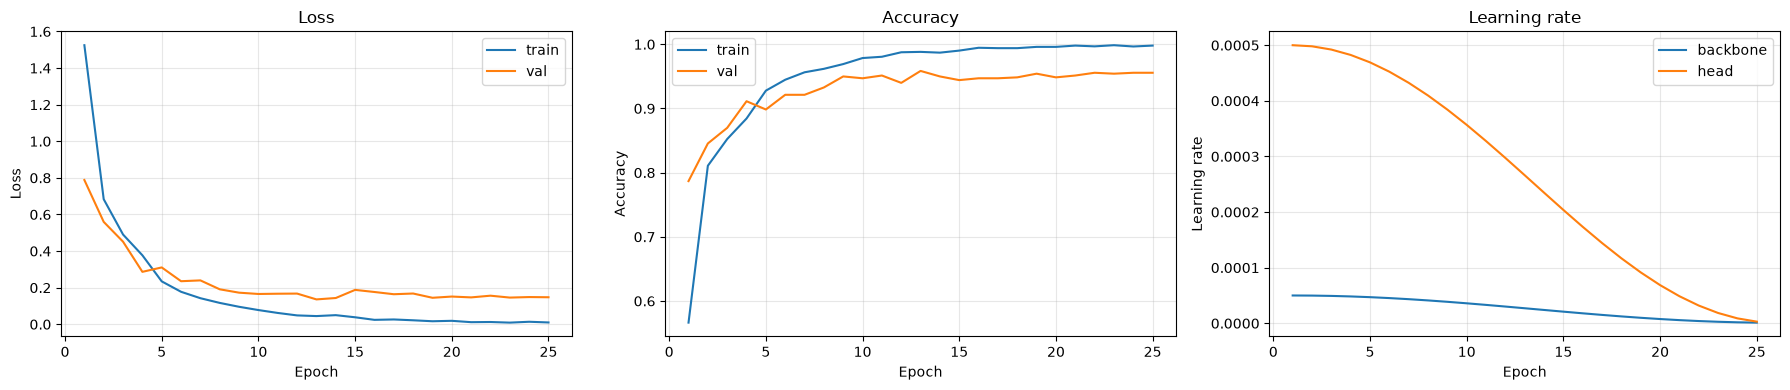

,model,correct,accuracy,fixed_by_robust,new_errors_robust
0,AGMFA robust,670,0.958512,NaN,NaN
1,stronger50,675,0.965665,8.0,13.0
2,AGMFA stronger,670,0.958512,0.0,0.0


Исправлено: 8; новых ошибок: 13; общих ошибок: 16


,id,true_label,stronger50_label,agmfe_label,stronger50_confidence,agmfe_confidence
2,45.jpg,5,3,5,0.650349,0.734703
14,233.jpg,2,2,9,0.999276,0.758345
72,1617.jpg,6,19,6,0.899272,0.577316
76,1685.jpg,8,2,8,0.900393,0.975801
159,3166.jpg,10,10,11,0.999973,0.617618
236,4761.jpg,17,3,5,0.845540,0.399588
252,5108.jpg,18,11,18,0.679817,0.988229
305,6146.jpg,11,9,11,0.966164,0.428460
328,6615.jpg,7,7,3,0.766654,0.575744
372,7548.jpg,3,3,5,0.662820,0.832206


Логи: C:\Users\peret\Desktop\Third year\ML\comp\comp 2\artifacts\logs\resnet50_agmfa_robust_augmix_001
Веса: C:\Users\peret\Desktop\Third year\ML\comp\comp 2\artifacts\models\resnet50_agmfa_robust_augmix_001
Вероятности: C:\Users\peret\Desktop\Third year\ML\comp\comp 2\artifacts\predictions\resnet50_agmfa_robust_augmix_001\val_probabilities.npz
Training row записана в experiments.csv; test inference не запускался.


In [7]:
from src.training.predict import load_probabilities
logs = ROOT/'artifacts/logs'/EXP_ID
predictions = ROOT/'artifacts/predictions'/EXP_ID
result = None
if not (logs/'summary.json').is_file():
    print('Новый recipe ещё не обучен. После Kaggle training выполните эту ячейку повторно.')
else:
    summary = json.loads((logs/'summary.json').read_text(encoding='utf-8'))
    display(pd.DataFrame([{'exp_id': EXP_ID, **summary}]))
    if result is None:
        plot_history(pd.read_csv(logs/'history.csv'), show=True)
    candidate = load_probabilities(predictions/'val_probabilities.npz').table(include_scores=True)
    new_ok = candidate.label.to_numpy() == candidate.true_label.to_numpy()
    rows = [{'model': 'AGMFA robust', 'correct': int(new_ok.sum()), 'accuracy': float(new_ok.mean())}]
    for name, run in [('stronger50', 'resnet50_partial_domain_shift_stronger_001'),
                      ('AGMFA stronger', 'resnet50_agmfa_robust_augmix_001')]:
        path = ROOT/'artifacts/predictions'/run/'val_probabilities.npz'
        if not path.is_file():
            continue
        old = load_probabilities(path).table(include_scores=True)
        if set(old.id) != set(candidate.id):
            raise ValueError('Val IDs отличаются; сравнение запрещено')
        old = old.set_index('id').loc[candidate.id].reset_index()
        if not (old.true_label.to_numpy() == candidate.true_label.to_numpy()).all():
            raise ValueError('Val labels отличаются; сравнение запрещено')
        old_ok = old.label.to_numpy() == old.true_label.to_numpy()
        rows.append({'model': name, 'correct': int(old_ok.sum()), 'accuracy': float(old_ok.mean()),
                     'fixed_by_robust': int((~old_ok & new_ok).sum()),
                     'new_errors_robust': int((old_ok & ~new_ok).sum())})
    display(pd.DataFrame(rows))

    baseline_path = ROOT / 'artifacts/predictions/resnet50_partial_domain_shift_stronger_001/val_probabilities.npz'
    if baseline_path.is_file():
        baseline = load_probabilities(baseline_path).table(include_scores=True)
        baseline = baseline.set_index('id').reindex(candidate.id).reset_index()
        if baseline.label.isna().any() or len(baseline) != len(candidate):
            raise ValueError('Baseline/candidate val IDs не совпадают')
        if not (baseline.true_label.to_numpy() == candidate.true_label.to_numpy()).all():
            raise ValueError('Baseline/candidate val targets не совпадают')
        old_ok = baseline.label.to_numpy() == baseline.true_label.to_numpy()
        new_ok = candidate.label.to_numpy() == candidate.true_label.to_numpy()
        print(f'Исправлено: {int((~old_ok & new_ok).sum())}; новых ошибок: {int((old_ok & ~new_ok).sum())}; '
                f'общих ошибок: {int((~old_ok & ~new_ok).sum())}')
        changed = pd.DataFrame({'id': candidate.id, 'true_label': candidate.true_label,
                                        'stronger50_label': baseline.label, 'agmfe_label': candidate.label,
                                        'stronger50_confidence': baseline.confidence, 'agmfe_confidence': candidate.confidence})
        display(changed[changed.stronger50_label != changed.agmfe_label].head(30))
    else:
        print('Baseline val_probabilities.npz отсутствует; сохранённый результат AGMFA показан выше.')
        
    print(f'Логи: {logs}')
    print(f'Веса: {ROOT/"artifacts/models"/EXP_ID}')
    print(f'Вероятности: {predictions/"val_probabilities.npz"}')
    print('Training row записана в experiments.csv; test inference не запускался.')


In [8]:
from pathlib import Path
import shutil
import zipfile

ARTIFACTS = Path("/kaggle/working/project/artifacts")
EXP_ID = "resnet50_agmfa_robust_augmix_001"
OUTPUT_DIR = Path("/kaggle/working")

# logs и predictions как раньше
targets = {
    "logs": ARTIFACTS / "logs" / EXP_ID,
    "predictions": ARTIFACTS / "predictions" / EXP_ID,
}

for name, folder in targets.items():
    if not folder.exists():
        print(f"SKIP: {folder} не существует")
        continue

    output_base = OUTPUT_DIR / f"{EXP_ID}_{name}"

    shutil.make_archive(
        str(output_base),
        "zip",
        root_dir=folder
    )

    print(f"Created: {output_base}.zip")


# models отдельно: best и last
models_dir = ARTIFACTS / "models" / EXP_ID

if models_dir.exists():
    for model_type in ["best", "last"]:
        files = [
            p for p in models_dir.rglob("*")
            if p.is_file() and model_type.lower() in p.name.lower()
        ]

        if not files:
            print(f"SKIP: model '{model_type}' не найден")
            continue

        zip_path = OUTPUT_DIR / f"{EXP_ID}_{model_type}.zip"

        with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
            for file in files:
                z.write(
                    file,
                    arcname=file.relative_to(models_dir)
                )

        print(f"Created: {zip_path}")
else:
    print(f"SKIP: {models_dir} не существует")

Created: /kaggle/working/resnet50_agmfa_robust_augmix_001_logs.zip
Created: /kaggle/working/resnet50_agmfa_robust_augmix_001_predictions.zip
Created: /kaggle/working/resnet50_agmfa_robust_augmix_001_best.zip
Created: /kaggle/working/resnet50_agmfa_robust_augmix_001_last.zip
